# 09 - Failure Analysis

Evidence for the failure modes in `docs/RESULTS.md`. Probes were written on dev and run unchanged on held-out.

In [1]:
import pandas as pd
from IPython.display import Image, display
RESULTS = "../docs/results/"
FIGURES = "../docs/figures/"
pd.set_option("display.width", 200, "display.max_columns", 30)

## Failure mode 1: function words create detections of absent objects

In [2]:
pd.concat([pd.read_csv(RESULTS + f"token_summary_{r}.csv").assign(role=r) for r in ("dev", "heldout")]).round(3)

,class_name,prompt,images,structural_winner,fire_rate,content_fire_rate,top_token,role
0,Box,a box,60,0.567,0.933,0.917,a,dev
1,Box,a fallen box,60,0.383,0.983,0.967,a,dev
2,Box,a photo of a box,60,0.933,0.867,0.250,a,dev
3,Box,box,60,0.000,0.583,0.583,box,dev
4,Box,no box,60,0.000,0.950,0.950,box,dev
5,Forklift truck,a forklift,60,0.150,0.900,0.883,fork,dev
6,Forklift truck,a giraffe,60,0.983,0.600,0.400,a,dev
7,Forklift truck,a photo of a forklift,60,0.650,0.983,0.750,a,dev
8,Forklift truck,forklift,60,0.000,0.850,0.850,##lift,dev
9,Forklift truck,giraffe,60,0.000,0.033,0.033,gi,dev


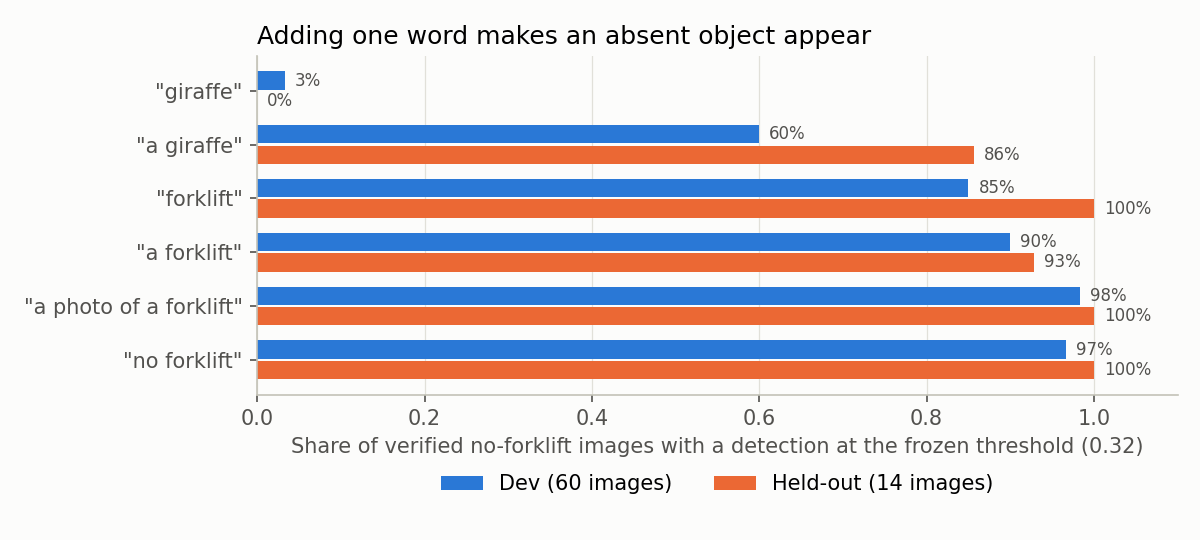

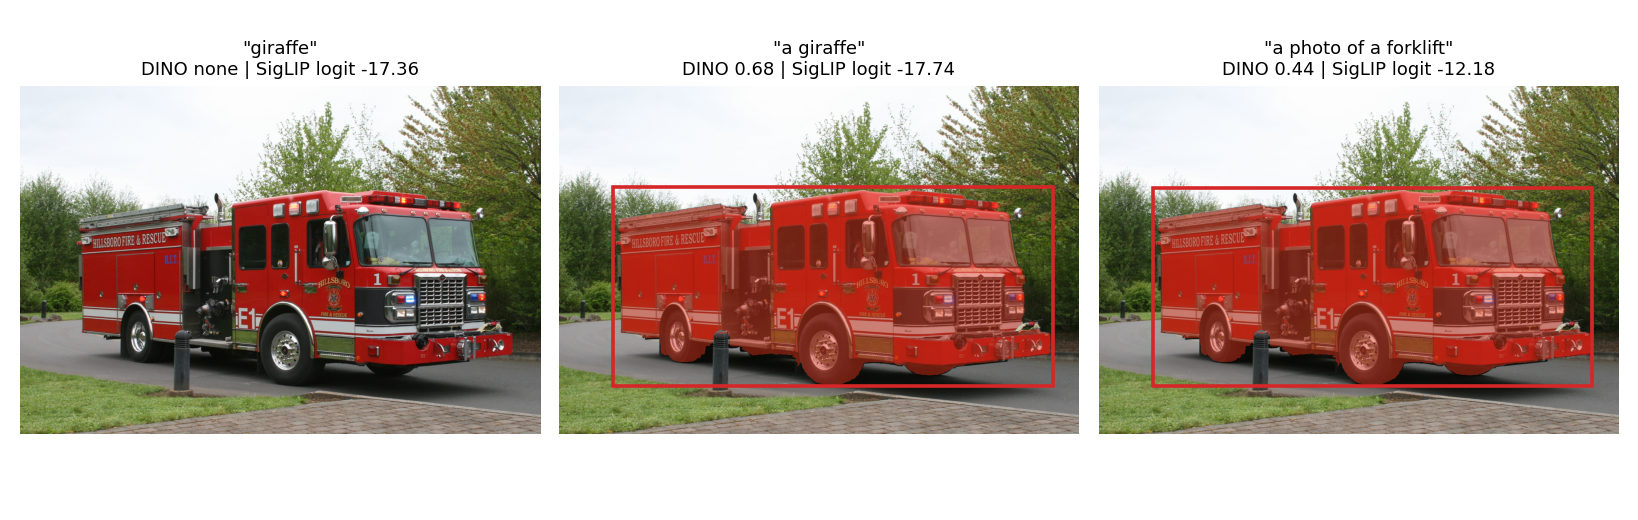

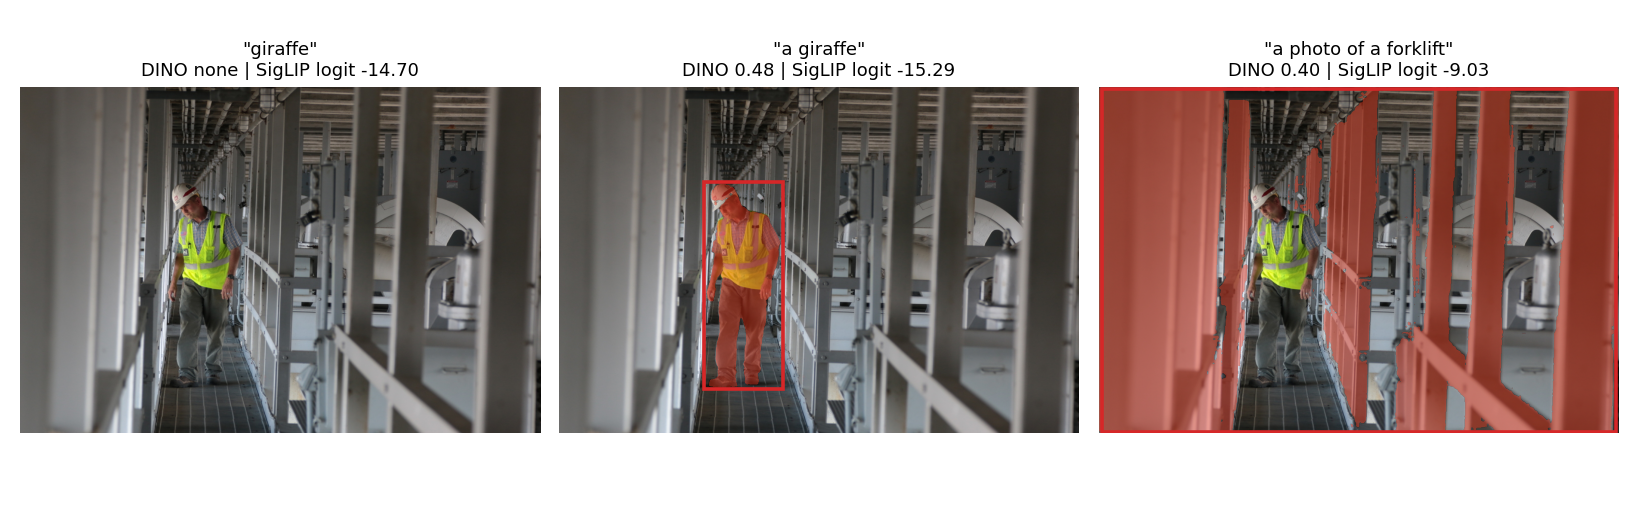

In [3]:
display(Image(FIGURES + "absent_object_fire_rate.png"))
display(Image(FIGURES + "hallucination_0.png"))
display(Image(FIGURES + "hallucination_1.png"))

## Failure mode 2: negation and state are ignored

In [4]:
probe = pd.read_csv(RESULTS + "modifier_heldout.csv")
probe.assign(fires=probe["score"] >= 0.32, same_box=probe["top_box_iou"] >= 0.9).groupby(["class_name", "prompt"])[["fires", "same_box", "score"]].mean().round(3)

fires  same_box  score
class_name     prompt                                             
Box            a crushed box                0.967     0.850  0.595
               a damaged box                0.967     0.850  0.560
               a fallen box                 0.983     0.833  0.568
               no box                       0.967     0.883  0.562
               not a box                    0.983     0.917  0.615
Forklift truck a damaged forklift           1.000     0.920  0.636
               no forklift                  1.000     1.000  0.682
               not a forklift               1.000     1.000  0.708
Person         a fallen person              0.950     0.583  0.510
               a person lying on the floor  0.783     0.533  0.465
               no person                    0.900     0.600  0.456
               not a person                 0.933     0.783  0.510

,role,class_name,prompt,n_pos,n_neg,auroc,pos_score_mean,text_cosine_to_base,correlation_with_base
0,heldout,Forklift truck,a forklift,25,14,0.971,0.386,1.000,1.000
1,heldout,Forklift truck,no forklift,25,14,0.926,0.028,0.881,0.942
2,heldout,Forklift truck,not a forklift,25,14,0.889,0.212,0.917,0.901
3,heldout,Forklift truck,a damaged forklift,25,14,0.946,0.170,0.874,0.938
4,heldout,Box,a box,185,125,0.605,0.027,1.000,1.000
5,heldout,Box,no box,185,125,0.553,0.001,0.830,0.878
6,heldout,Box,not a box,185,125,0.570,0.015,0.910,0.929
7,heldout,Box,a fallen box,185,125,0.584,0.026,0.883,0.892
8,heldout,Box,a damaged box,185,125,0.607,0.024,0.838,0.877
9,heldout,Person,a person,420,532,0.774,0.000,1.000,1.000


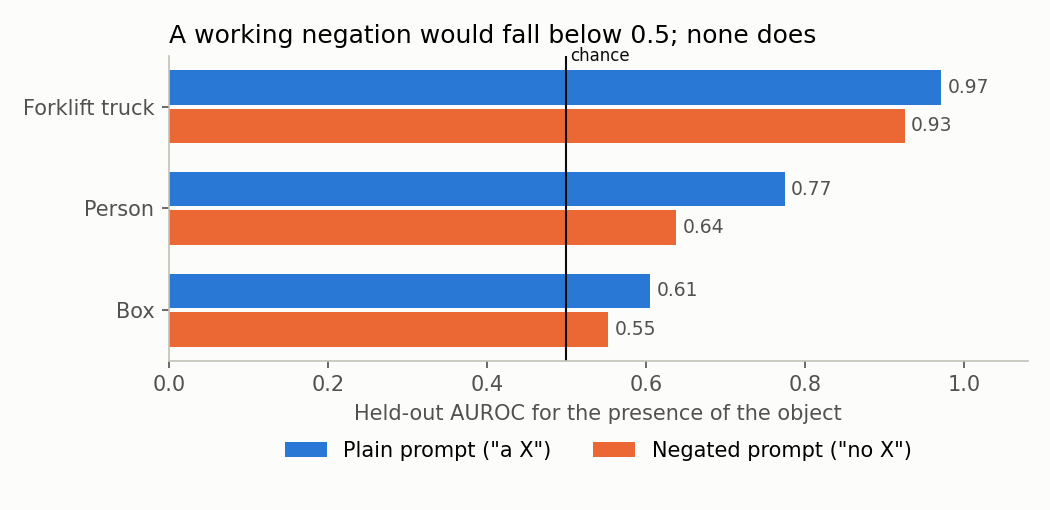

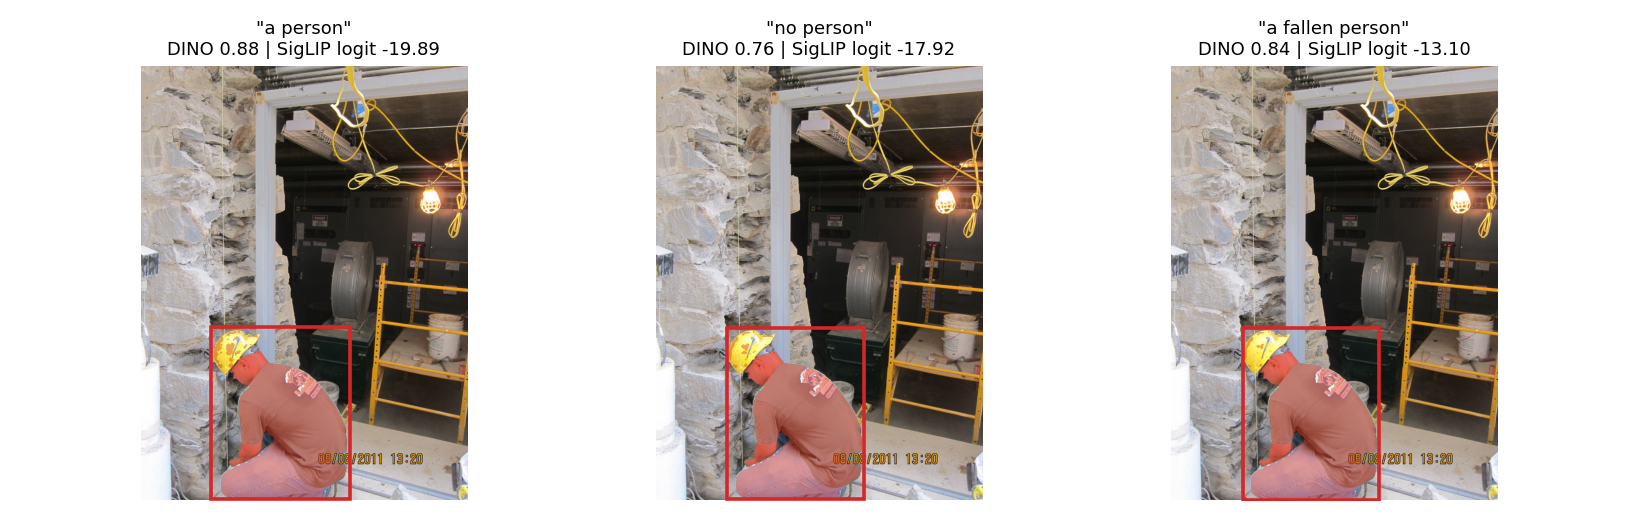

In [5]:
display(pd.read_csv(RESULTS + "siglip_negation_heldout.csv").round(3))
display(Image(FIGURES + "siglip_negation_auroc.png"))
display(Image(FIGURES + "negation_0.png"))

## Failure mode 3: the detector cannot reject lookalikes or scene-level concepts

In [6]:
siglip = pd.read_csv(RESULTS + "siglip_heldout.csv").query("condition == 'photo'").set_index("class_name")["auroc"]
detector = pd.read_csv(RESULTS + "detector_heldout.csv").query("condition == 'bare'").set_index("class_name")["image_auroc"]
points = pd.read_csv(RESULTS + "operating_point_heldout.csv").set_index("class_name")["false_positive_rate"]
pd.DataFrame({"siglip_auroc": siglip, "detector_auroc": detector, "detector_fpr": points}).round(3).sort_values("detector_auroc")

,siglip_auroc,detector_auroc,detector_fpr
class_name,,,
Hard hat,0.896,0.424,1.000
Cardboard,0.356,0.431,1.000
Inventory,0.793,0.467,0.986
Shelving,0.934,0.491,0.923
Warehouse,0.796,0.519,1.000
Truck,0.711,0.555,0.904
Box,0.604,0.605,0.792
Forklift truck,0.971,0.669,1.000
Aisle,0.767,0.680,0.962


## Mechanism: SigLIP occlusion

The image is labeled as a forklift in Open Images but shows a street sweeper.

,images,median_abs_diff,p95_abs_diff,max_abs_diff,pearson,check,median_map_correlation
0,100,0.0062,0.0409,0.0505,0.996,batch_vs_single,NaN
1,20,NaN,NaN,NaN,NaN,occlusion,0.6642


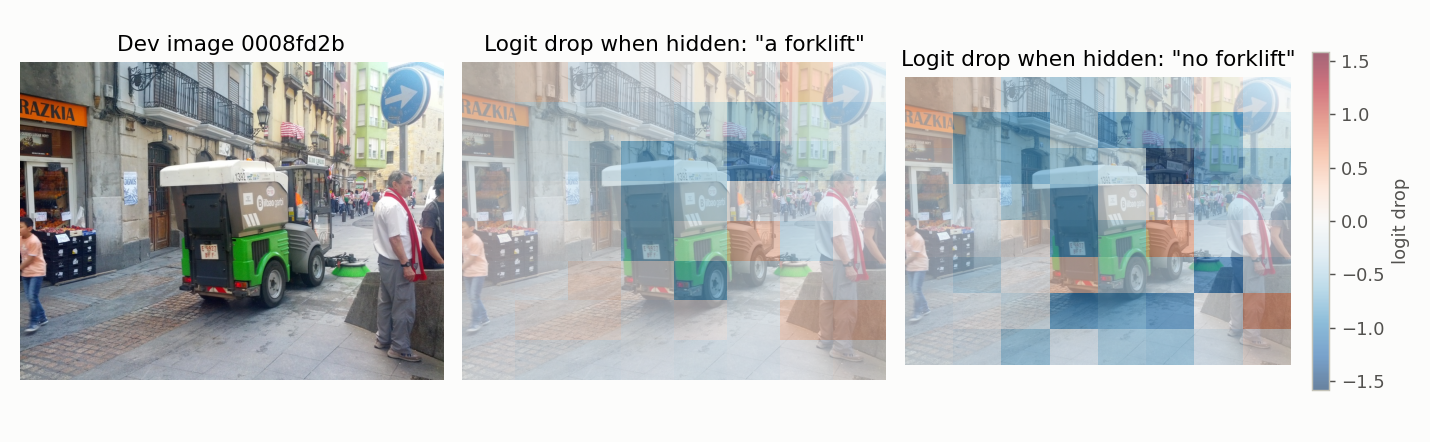

In [7]:
display(pd.read_csv(RESULTS + "checks.csv").round(4))
display(Image(FIGURES + "siglip_occlusion.png"))